# Кто вообще есть?

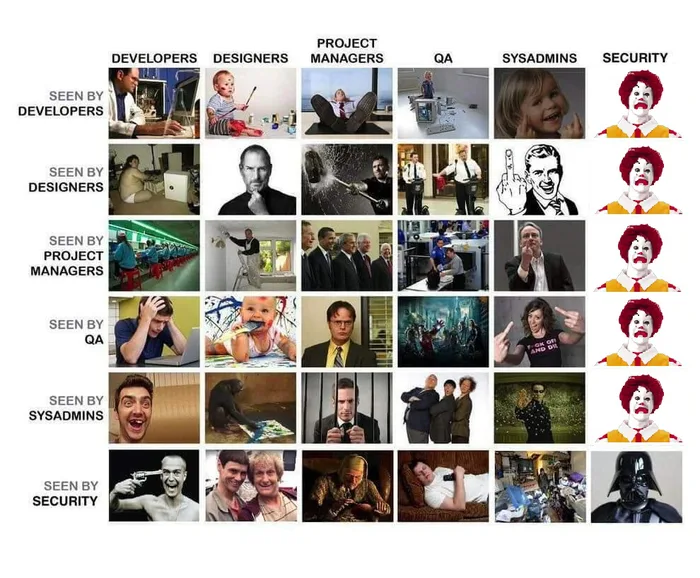

Ну а если серьезно, рассмотрим такие роли:
- сетевик
- инфраструктурщик
- разработчик
- аналитик
- архитектор
- ибшник

# Сетевики

Занимаются они вопросами сетевой связности, настраивают VPN и т.д.

В целом про сеть мы уже говорили на прошлой лекции, но у нас осталось несколько пробелов

## DNS

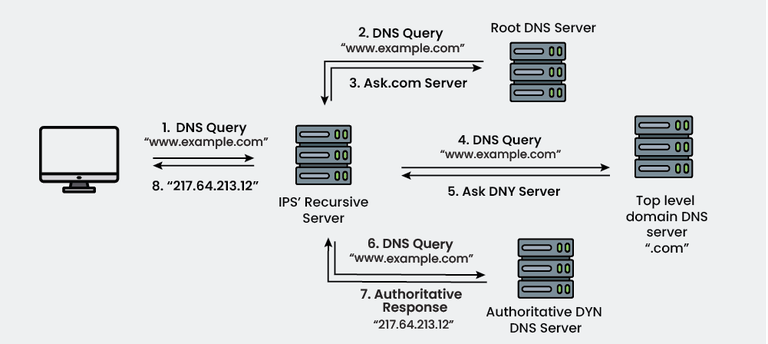

Алгоритм такой - пусть ищем my.test.com:
- смотрим локально в hosts
- спрашиваем у корневого сервера
- он отвечает, какой сервер ответственен за зону .com
- обращаемся к ответственному за зону .com
- он отвечает, какой сервер ответсвенен за зону test.com
- обращаемся к ответственному за зону test.com
- он отдает ip, за которым живет my.test.com

In [ ]:
# 127.0.0.1  localhost
# 255.255.255.255  broadcasthost
# 192.168.1.2 host.docker.internal
# 192.168.1.2 gateway.docker.internal

In [1]:
!nslookup google.com

Server:		127.0.0.11
Address:	127.0.0.11#53

Non-authoritative answer:
Name:	google.com
Address: 192.178.142.102
Name:	google.com
Address: 192.178.142.138
Name:	google.com
Address: 192.178.142.100
Name:	google.com
Address: 192.178.142.101
Name:	google.com
Address: 192.178.142.113
Name:	google.com
Address: 192.178.142.139
Name:	google.com
Address: 2607:f8b0:4023:807::8b
Name:	google.com
Address: 2607:f8b0:4023:807::65
Name:	google.com
Address: 2607:f8b0:4023:807::71
Name:	google.com
Address: 2607:f8b0:4023:807::64



Записи бывают разных типов:
- A (IPv4)
- AAAA (IPv6)
- CNAME (другое имя)
- NS (DNS сервер)
- ...

301 код (редирект) и наличие CNAME то РАЗНЫЕ вещи

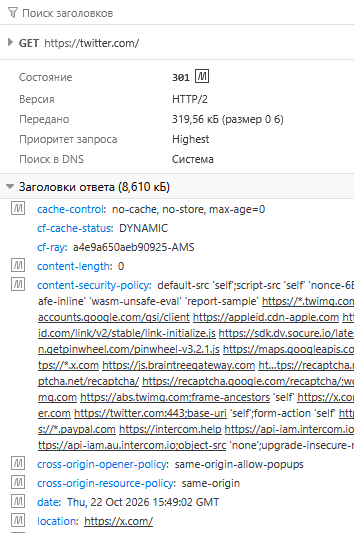

In [2]:
!dig google.com A


; <<>> DiG 9.18.39-0ubuntu0.24.04.8-Ubuntu <<>> google.com A
;; global options: +cmd
;; Got answer:
;; ->>HEADER<<- opcode: QUERY, status: NOERROR, id: 61244
;; flags: qr rd ra; QUERY: 1, ANSWER: 6, AUTHORITY: 0, ADDITIONAL: 1

;; OPT PSEUDOSECTION:
; EDNS: version: 0, flags:; udp: 512
;; QUESTION SECTION:
;google.com.			IN	A

;; ANSWER SECTION:
google.com.		300	IN	A	192.178.142.100
google.com.		300	IN	A	192.178.142.138
google.com.		300	IN	A	192.178.142.102
google.com.		300	IN	A	192.178.142.113
google.com.		300	IN	A	192.178.142.101
google.com.		300	IN	A	192.178.142.139

;; Query time: 3 msec
;; SERVER: 127.0.0.11#53(127.0.0.11) (UDP)
;; WHEN: Thu Oct 22 15:50:50 UTC 2026
;; MSG SIZE  rcvd: 135



In [3]:
!dig google.com AAAA


; <<>> DiG 9.18.39-0ubuntu0.24.04.8-Ubuntu <<>> google.com AAAA
;; global options: +cmd
;; Got answer:
;; ->>HEADER<<- opcode: QUERY, status: NOERROR, id: 62889
;; flags: qr rd ra; QUERY: 1, ANSWER: 4, AUTHORITY: 0, ADDITIONAL: 1

;; OPT PSEUDOSECTION:
; EDNS: version: 0, flags:; udp: 512
;; QUESTION SECTION:
;google.com.			IN	AAAA

;; ANSWER SECTION:
google.com.		300	IN	AAAA	2607:f8b0:4023:80b::64
google.com.		300	IN	AAAA	2607:f8b0:4023:80b::71
google.com.		300	IN	AAAA	2607:f8b0:4023:80b::8b
google.com.		300	IN	AAAA	2607:f8b0:4023:80b::66

;; Query time: 2 msec
;; SERVER: 127.0.0.11#53(127.0.0.11) (UDP)
;; WHEN: Thu Oct 22 15:51:18 UTC 2026
;; MSG SIZE  rcvd: 151



In [4]:
!dig google.com NS


; <<>> DiG 9.18.39-0ubuntu0.24.04.8-Ubuntu <<>> google.com NS
;; global options: +cmd
;; Got answer:
;; ->>HEADER<<- opcode: QUERY, status: NOERROR, id: 40628
;; flags: qr rd ra; QUERY: 1, ANSWER: 4, AUTHORITY: 0, ADDITIONAL: 1

;; OPT PSEUDOSECTION:
; EDNS: version: 0, flags:; udp: 512
;; QUESTION SECTION:
;google.com.			IN	NS

;; ANSWER SECTION:
google.com.		21600	IN	NS	ns2.google.com.
google.com.		21600	IN	NS	ns4.google.com.
google.com.		21600	IN	NS	ns1.google.com.
google.com.		21600	IN	NS	ns3.google.com.

;; Query time: 13 msec
;; SERVER: 127.0.0.11#53(127.0.0.11) (UDP)
;; WHEN: Thu Oct 22 15:52:36 UTC 2026
;; MSG SIZE  rcvd: 111



In [5]:
!dig skpp.transport.gov.ru CNAME


; <<>> DiG 9.18.39-0ubuntu0.24.04.8-Ubuntu <<>> skpp.transport.gov.ru CNAME
;; global options: +cmd
;; Got answer:
;; ->>HEADER<<- opcode: QUERY, status: NOERROR, id: 47564
;; flags: qr rd ra; QUERY: 1, ANSWER: 1, AUTHORITY: 0, ADDITIONAL: 1

;; OPT PSEUDOSECTION:
; EDNS: version: 0, flags:; udp: 512
;; QUESTION SECTION:
;skpp.transport.gov.ru.		IN	CNAME

;; ANSWER SECTION:
skpp.transport.gov.ru.	300	IN	CNAME	skpp.aoglonass.ru.

;; Query time: 1795 msec
;; SERVER: 127.0.0.11#53(127.0.0.11) (UDP)
;; WHEN: Thu Oct 22 15:53:59 UTC 2026
;; MSG SIZE  rcvd: 79



In [6]:
!dig skpp.aoglonass.ru A


; <<>> DiG 9.18.39-0ubuntu0.24.04.8-Ubuntu <<>> skpp.aoglonass.ru A
;; global options: +cmd
;; Got answer:
;; ->>HEADER<<- opcode: QUERY, status: NOERROR, id: 12649
;; flags: qr rd ra; QUERY: 1, ANSWER: 1, AUTHORITY: 0, ADDITIONAL: 1

;; OPT PSEUDOSECTION:
; EDNS: version: 0, flags:; udp: 512
;; QUESTION SECTION:
;skpp.aoglonass.ru.		IN	A

;; ANSWER SECTION:
skpp.aoglonass.ru.	3600	IN	A	193.232.47.112

;; Query time: 179 msec
;; SERVER: 127.0.0.11#53(127.0.0.11) (UDP)
;; WHEN: Thu Oct 22 15:54:27 UTC 2026
;; MSG SIZE  rcvd: 62



In [7]:
!dig skpp.transport.gov.ru A


; <<>> DiG 9.18.39-0ubuntu0.24.04.8-Ubuntu <<>> skpp.transport.gov.ru A
;; global options: +cmd
;; Got answer:
;; ->>HEADER<<- opcode: QUERY, status: NOERROR, id: 45518
;; flags: qr rd ra; QUERY: 1, ANSWER: 2, AUTHORITY: 0, ADDITIONAL: 1

;; OPT PSEUDOSECTION:
; EDNS: version: 0, flags:; udp: 512
;; QUESTION SECTION:
;skpp.transport.gov.ru.		IN	A

;; ANSWER SECTION:
skpp.transport.gov.ru.	300	IN	CNAME	skpp.aoglonass.ru.
skpp.aoglonass.ru.	3600	IN	A	193.232.47.112

;; Query time: 3061 msec
;; SERVER: 127.0.0.11#53(127.0.0.11) (UDP)
;; WHEN: Thu Oct 22 15:54:44 UTC 2026
;; MSG SIZE  rcvd: 95



## VPN

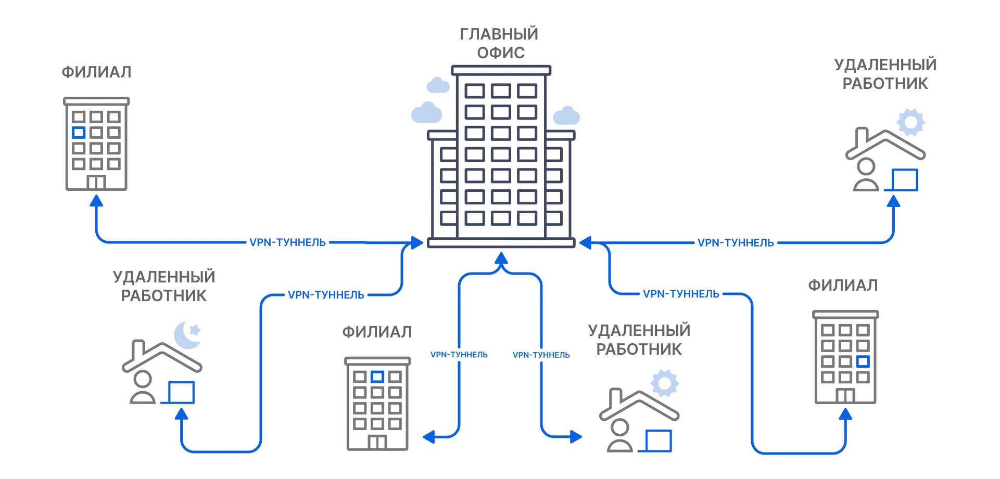

Нужен для:
- шифрования трафика
- управления доступом
- управления сетью

# Инфраструктурщики

Занимаются они вопросами размещения, поддержки и т.д.

## Kubernetes

In [ ]:
def windows_create_file(path, name, rights):
  pass

def linux_create_file(path, name, rights_dict):
  pass

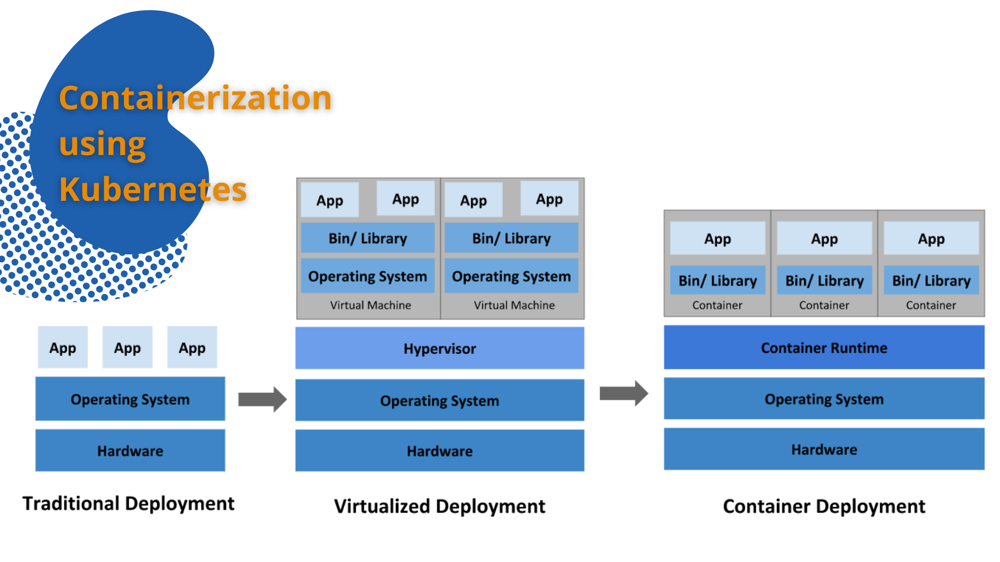

Кластер - физические сервера  
Неймспейсы - кусок, посвященный конкретному проекту (со своими лимитами)  
Контейнеры - сами наши приложения (со своими лимитами)

In [ ]:
FROM registry.services.mts.ru/docker/alpine/debug:3.11

ARG SERVICE_NAME='app'
ARG ARTIFACTS_PATH='artifacts'
ARG CONFIG_PATH='./configs/config.yaml'

ENV BINARY_NAME ${SERVICE_NAME}
ENV BINARY_PATH ${ARTIFACTS_PATH}
ENV CONFIG_PATH ${CONFIG_PATH}

COPY ${CONFIG_PATH} /etc/application/config.yaml
COPY ${BINARY_PATH}/${BINARY_NAME} /bin/${BINARY_NAME}

CMD /bin/${BINARY_NAME} -c /etc/application/config.yaml

Результат - образ  
Запущенный образ - контейнер

## CI/CD

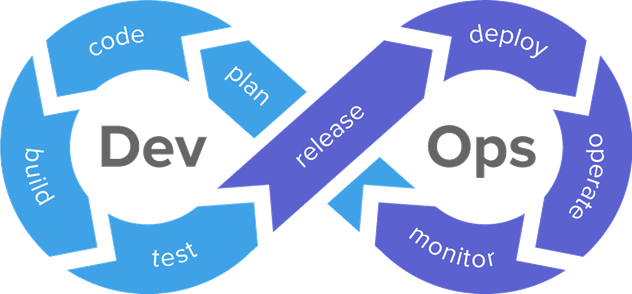

In [ ]:
# data/test.txt- commit3 v1.2.0-alpha.1
# main.py* data/test2.txt+ commit2 v1.1.0-rc.1
# main.py data/test.txt commit1 v1.0.0

In [ ]:
if 'alpha' in new_tag:
  return ['test', 'build', 'create image', 'deploy to develop']
elif 'rc' in new_tag:
  return ['test', 'build', 'create image', 'deploy to stage']
else:
  return ['test', 'build', 'create image', 'deploy to production']

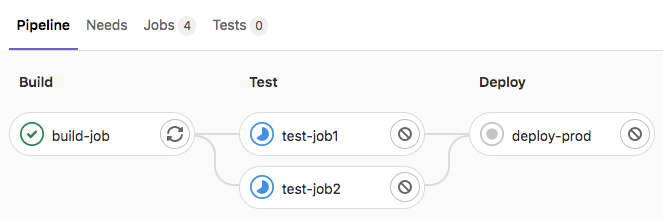

## Окружения

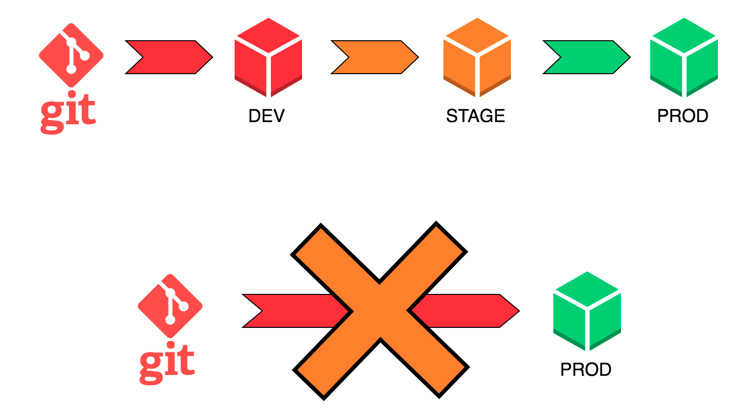

# Разработчик

Чем занимается разработчик, мы в целом понимаем и так)

## Системы контроля версий

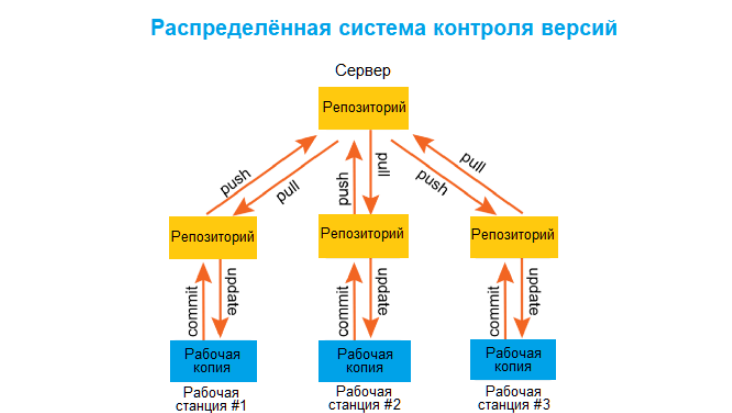

git init - иницируем репозиторий  
git add - добавляем что-то в коммит  
git commit - создаем коммит  
git push - пушим изменения на сервер  
git fetch - забирает изменения но не применяет  
git pull - и забирает, и применяет  
git checkout -b BRANCH_NAME - переходим на ветку  
git merge - сливает одну ветку в другую

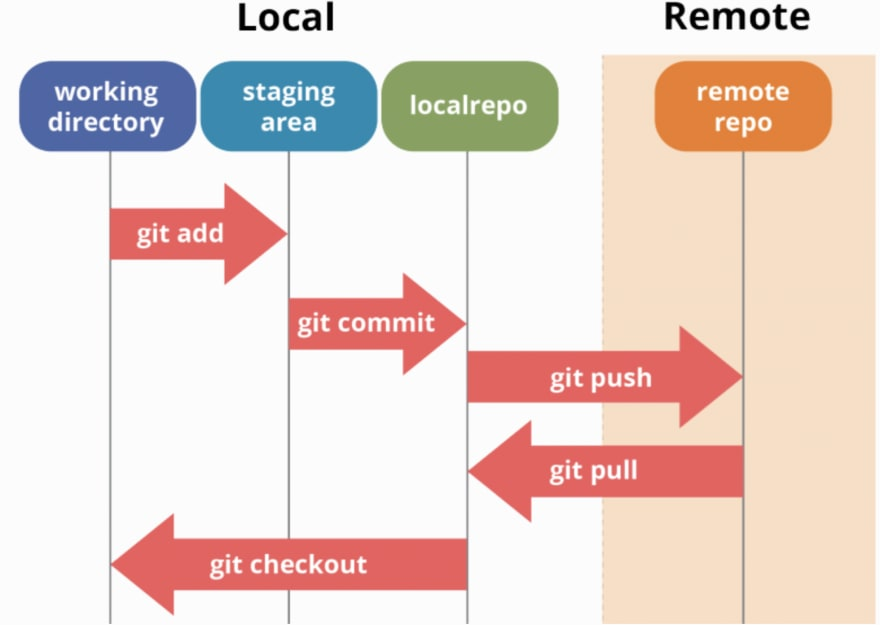

master/develop - основная ветка  
feature/TIS-12 - ветка с задачей  
fix/TIS-13 - ветка с багом

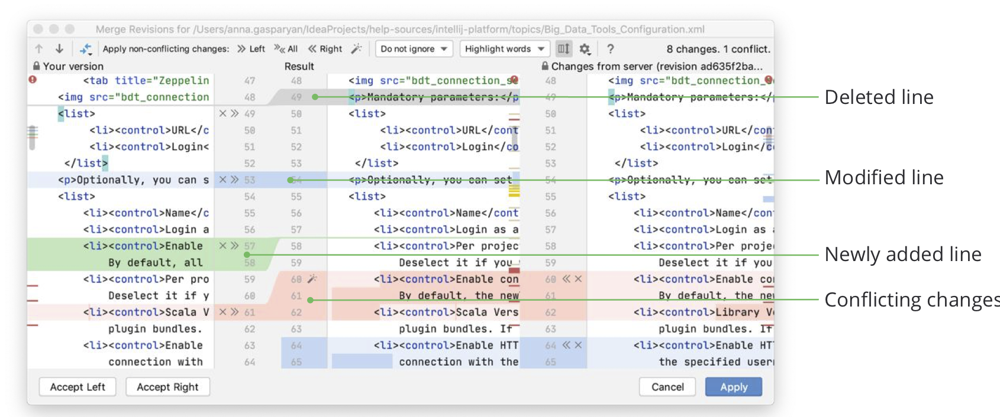

## Семантическое версионирование

https://semver.org/lang/ru/  
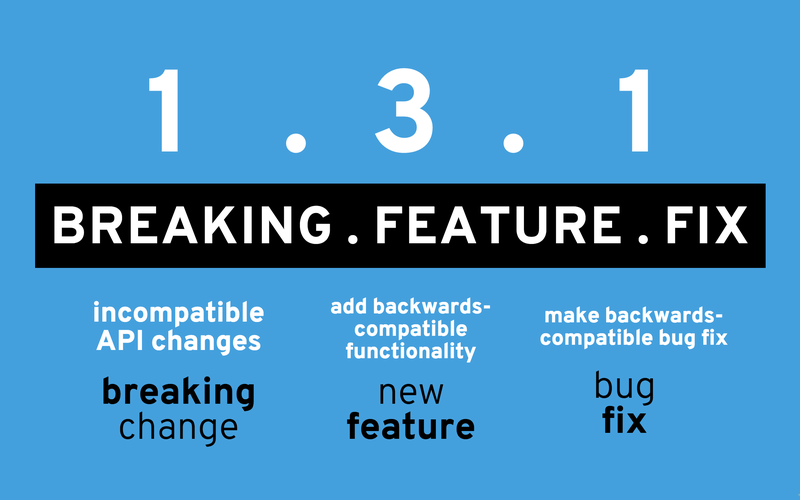

In [ ]:
# v1.0.0
class Place:
  def __init__(self):
    self.title = ""

def get_location(lat, long):
  return Place()

# v1.1.0
class Place:
  def __init__(self):
    self.title = ""
    self.description = ""

  def get_location(lat, long):
    return Place()

  def new_method(self):
    pass

# v1.2.0
class Place:
  def __init__(self):
    self.title = ""
    self.description = "DESCRIPTION

  def new_method(self):
    pass

# v1.2.1
class Place:
  def __init__(self):
    self.title = ""
    self.description = "DESCRIPTION"

  def new_method(self):
    pass

# v2.0.0
def get_location(lat, long):
  return [Place()]

In [ ]:
v1.0.0
v1.1.0-alpha.1 (dev)  (commit 1)
v1.1.0-alpha.2 (dev)  (commit 2)
v1.1.0-rc.1    (stage)(commit 2)
v1.1.0         (prod) (commit 2)

import numpy    (v1.19.2)  
import numpy/v2 (v2.0.0)

## Модификация поведения системы

### Конфиги

Для работы с конфигами есть довольно много вариантов. Посмотрим на базовый (configparser) и yaml

In [8]:
import configparser

In [9]:
config = configparser.ConfigParser()
config["DEFAULT"] = {
    "Compression": "yes",
    "CompressionLevel": "9",
}
config["test.org"] = {}
config["test.org"]["User"] = "admin"

In [10]:
with open("example.ini", "w") as configfile:
    config.write(configfile)

In [11]:
config = configparser.ConfigParser()
config.read("example.ini")
print("Sections:", config.sections())

Sections: ['test.org']


In [12]:
print(config.get('test.org', 'user'), config.get('test.org', 'compressionlevel'))

admin 9


In [13]:
import yaml

In [14]:
config = dict()
config["DEFAULT"] = {
    "Compression": "yes",
    "CompressionLevel": "9",
}
config["test.org"] = {}
config["test.org"]["user"] = "admin"

In [15]:
with open("example.yaml", "w") as configfile:
    yaml.dump(config, configfile)

In [16]:
with open("example.yaml", "r") as configfile:
    config = yaml.load(configfile, yaml.CLoader)

In [17]:
print(config['test.org']['user'])

admin


### Переменные окружения

Для того, чтобы чувствительные данные не передавались в открытом виде, обычно используют передачу их через переменные окружения

In [18]:
import os

In [19]:
os.getenv("APIKEY", "")

''

In [20]:
os.environ['APIKEY'] = '123'

In [21]:
os.getenv("APIKEY", "")

'123'

### Флаги

При запуске часто необходимые переменные передаются флагами, чтобы подсказать, где и что программе пытаться найти

Пример: python test.py -h

# Аналитик

Аналитик занимается ведением и проработкой задач

## Методологии

### Waterfall

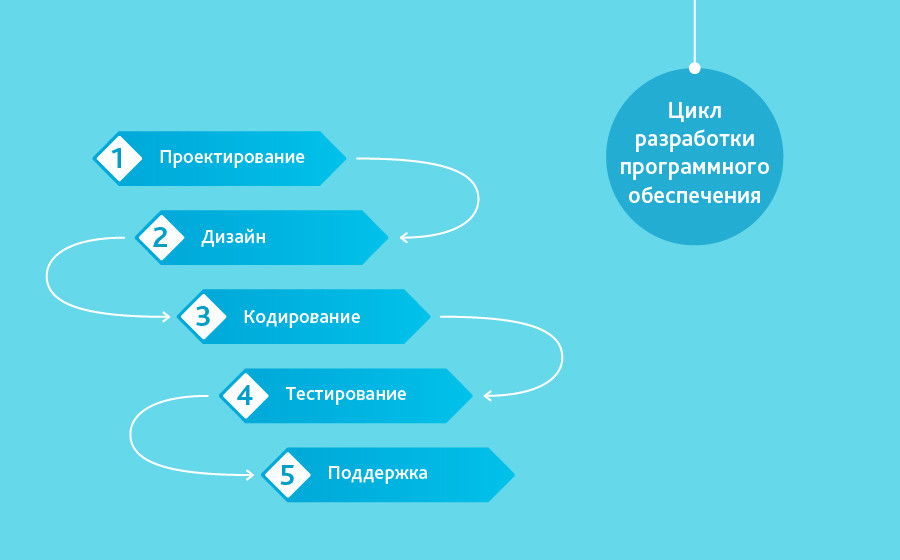

### Agile

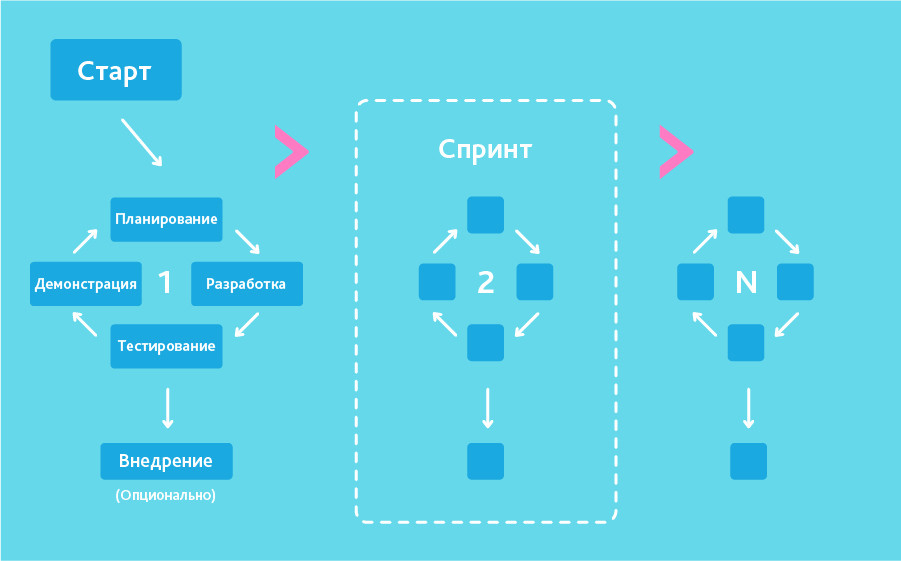

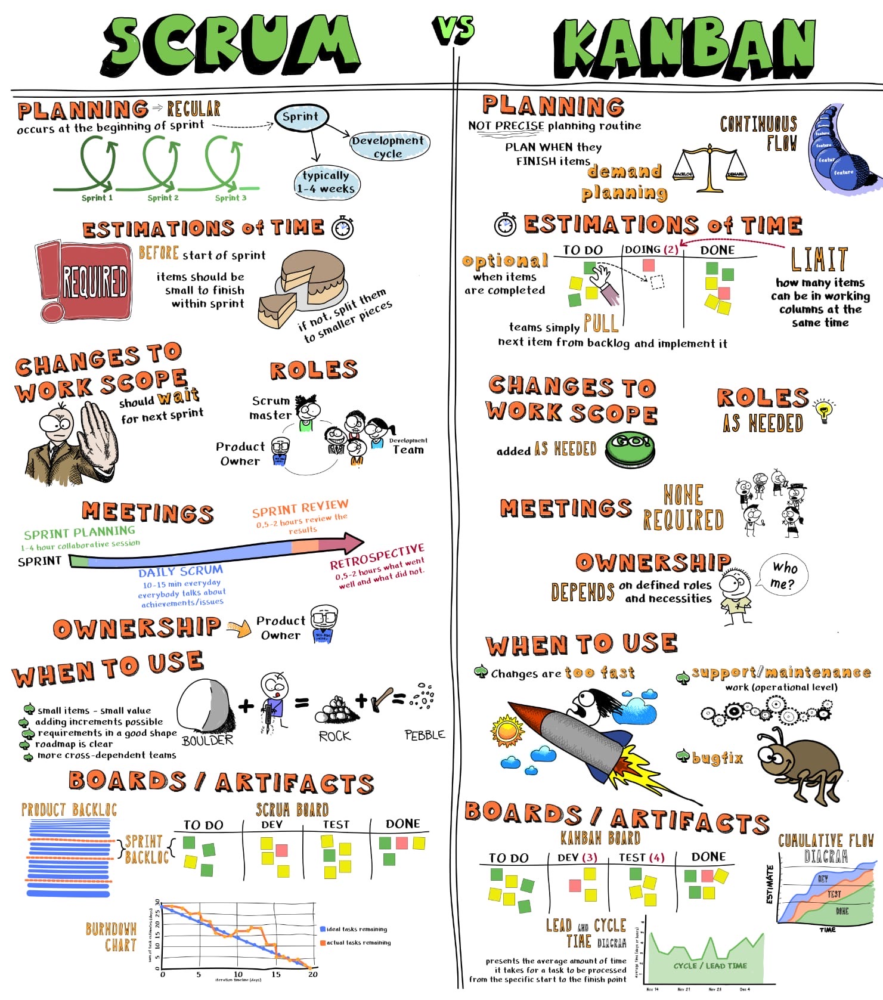

## Задачи

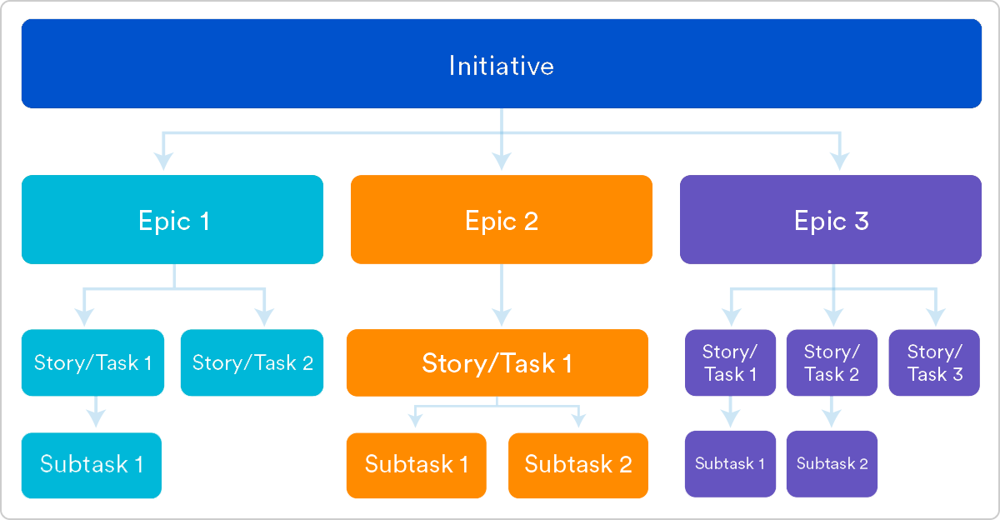

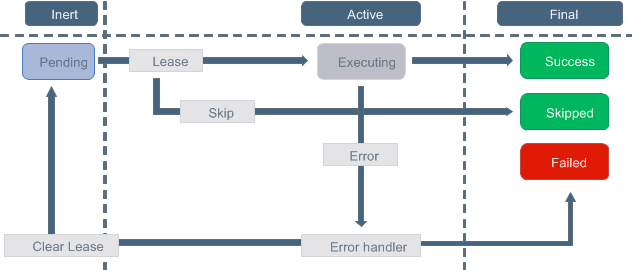

# Архитектор

Архитектор занимается проработкой решений на уровне продуктов и систем

## UML

Диаграмма развертывания
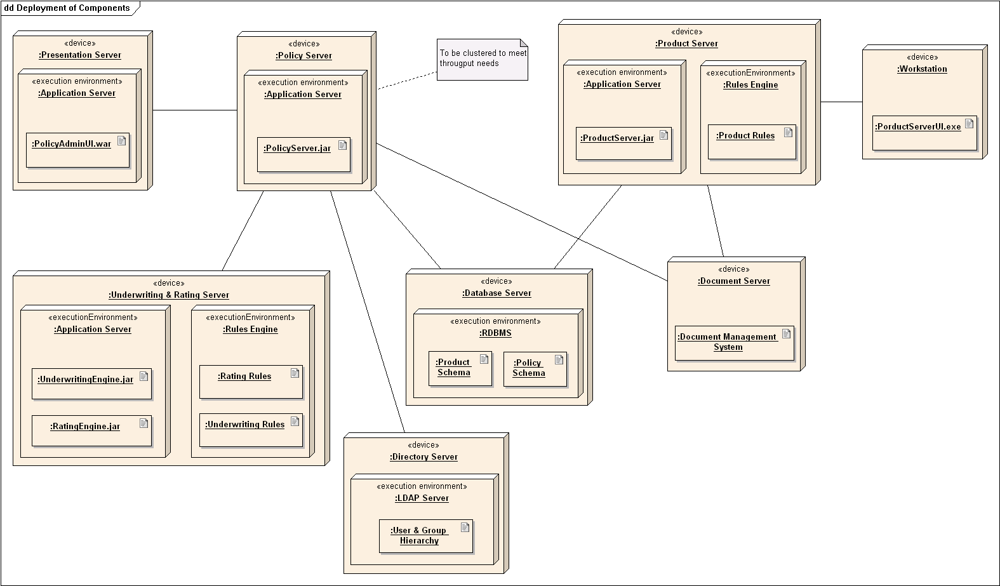

Диаграмма деятельности
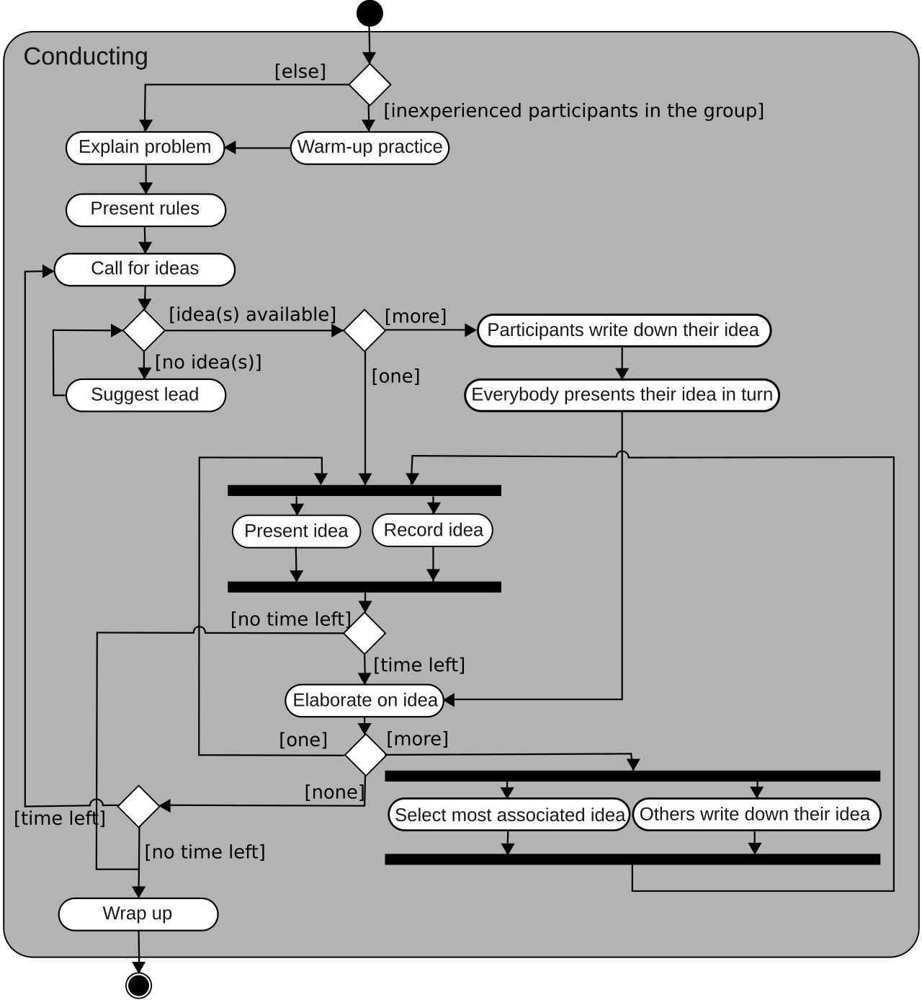

## C4

С4 нотация описывает 4 уровня взаимодействия:
- Context
- Containers
- Components
- Code

Context
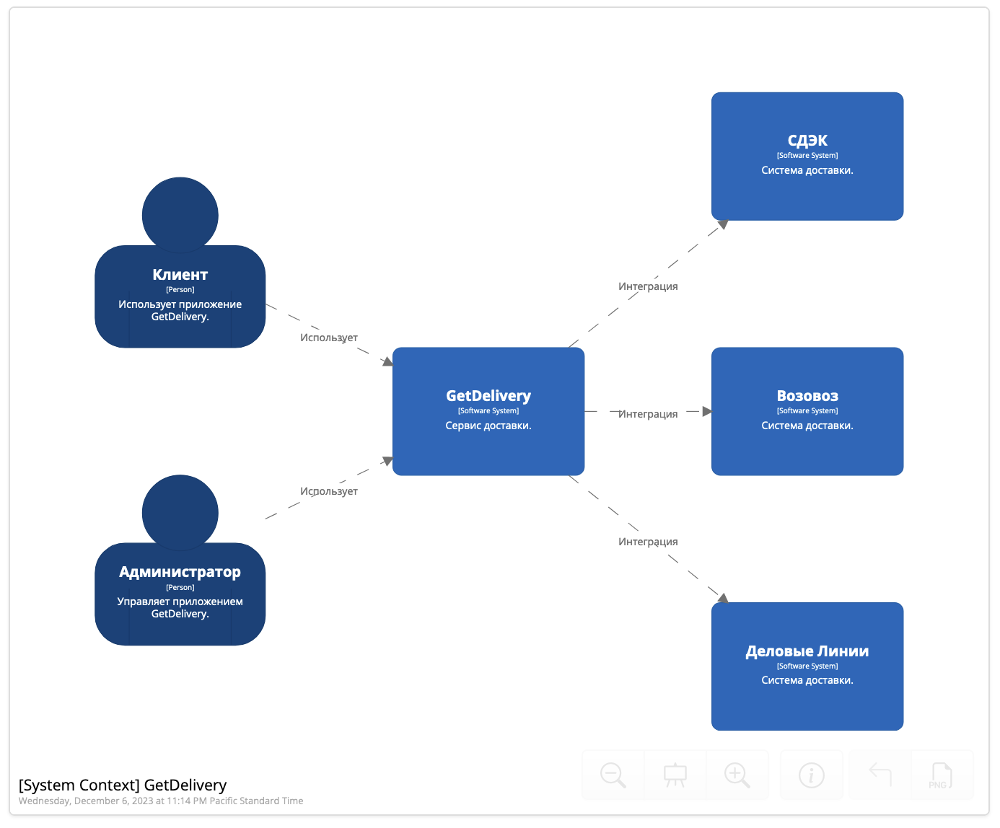

Container
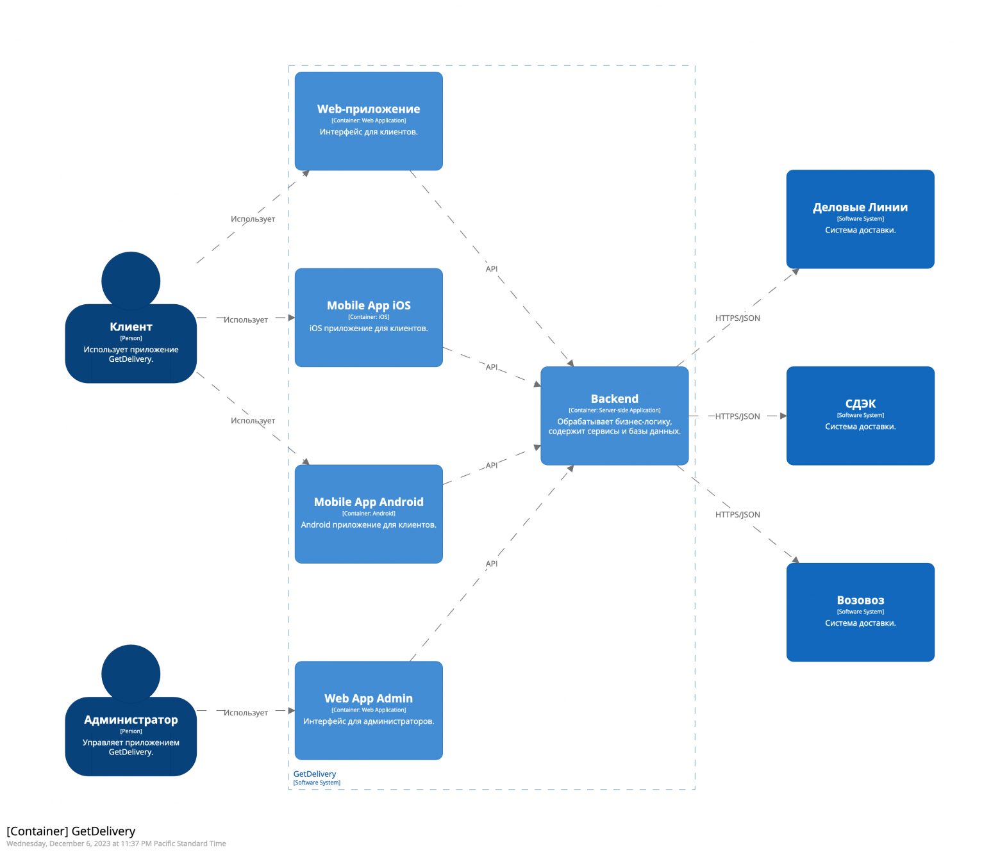

Component
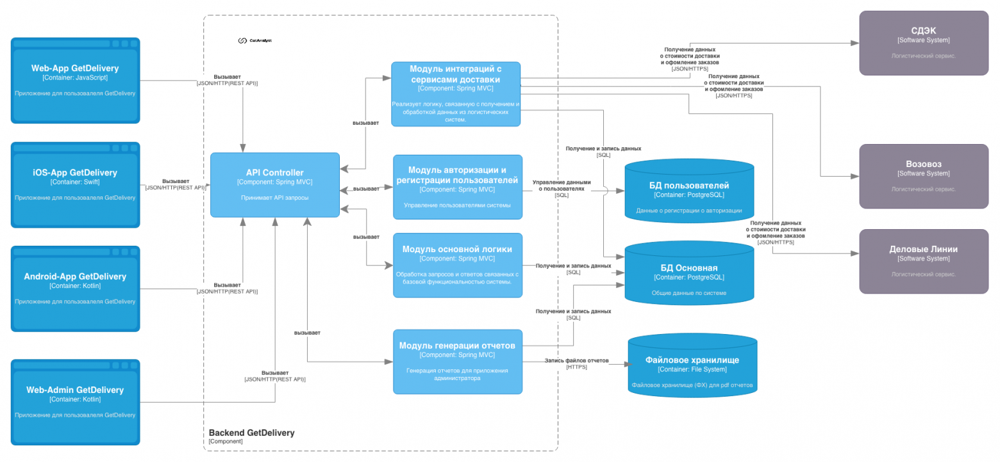

Code
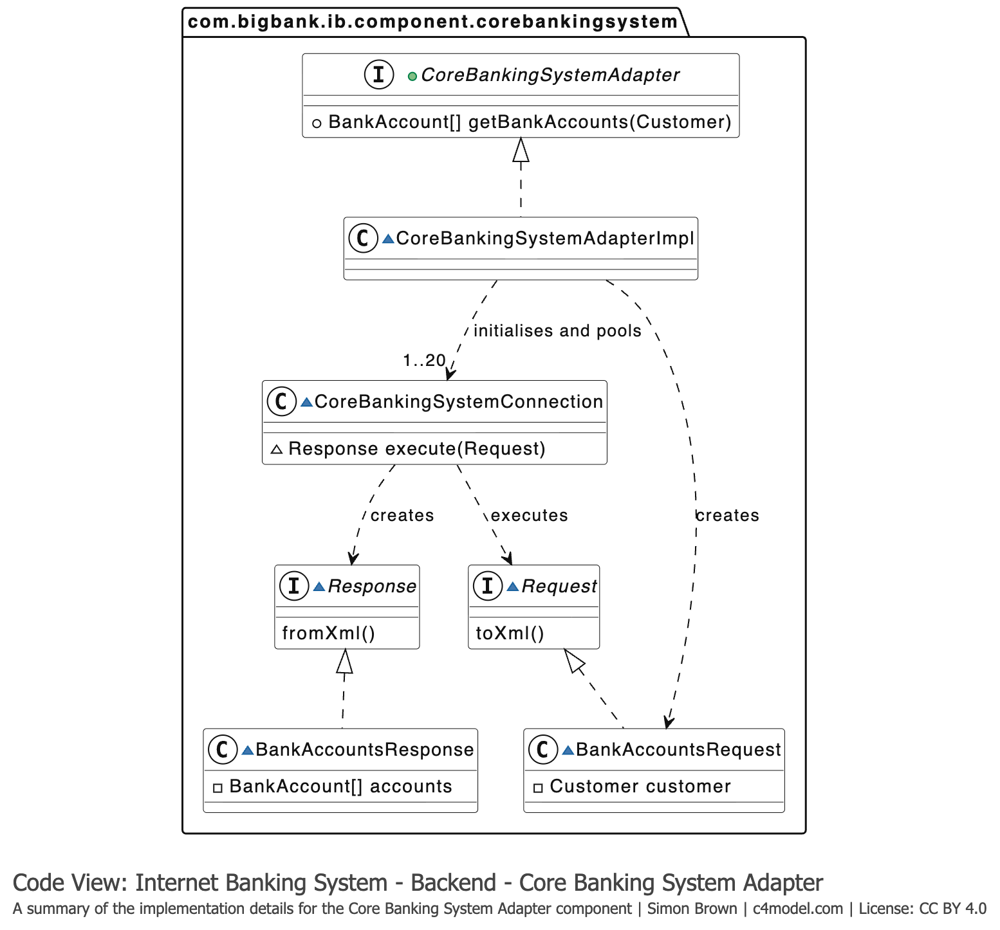

# ИБшник

ИБ занимаются тем, что мешают остальным работать

## Контуры

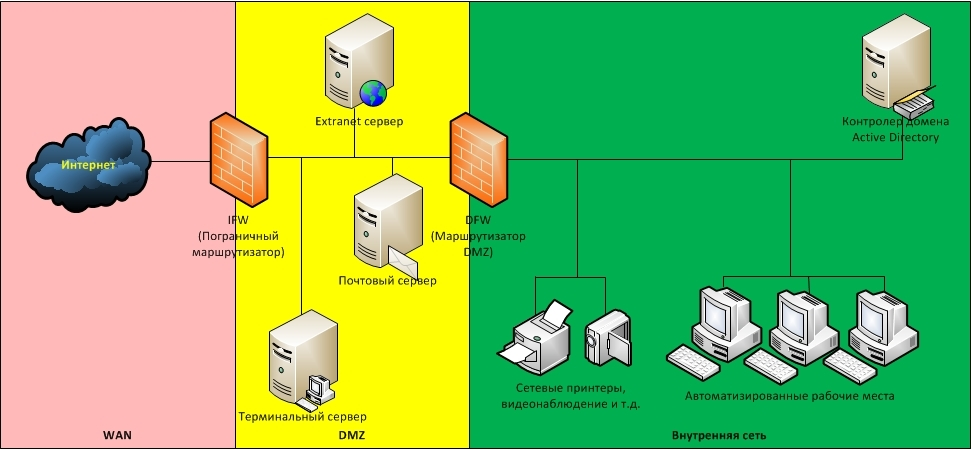

## CVE

CVE - публично известная уязвимость  
Называют в формате CVE-год-номер

https://nvd.nist.gov/vuln/detail/cve-2014-4650

## Персональные данные

Персональные данные - любая информация, относящаяся к прямо или косвенно определенному или определяемому физическому лицу (субъекту персональных данных)

Из Федеральный закон от 27.07.2006 N 152-ФЗ (ред. от 26.07.2026) "О персональных данных"

Категории:
- общедоступные (фио, место рождения, возраст и т.д.)
- биометрические
- специальные (полит. взгляды, вероисповедание и т.д.)
- иные (профессия, соц. статус)